In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
# 1. Wczytanie danych
vlagun_df = pd.read_csv('VLagun_Phys_Years3.csv')

In [3]:
# 2. Definicja X i Y dla VLagun
X_v = vlagun_df[['temp.', 'Windspeedinsitu']].values
y_v = vlagun_df['Years'].values

In [4]:
# 3. Podział na zbiór treningowy i testowy (30% test)
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_v, y_v, test_size=0.30, random_state=42)

In [5]:
# 4. Skalowanie cech
sc_v = StandardScaler()
X_train_v = sc_v.fit_transform(X_train_v)
X_test_v = sc_v.transform(X_test_v)

In [6]:
# DODANO BRAKUJĄCĄ ZMIENNĄ KERNELS:
kernels = ['linear', 'rbf', 'poly', 'sigmoid']

best_acc_v = 0
best_kernel_v = ''

In [7]:
print("\n--- ANALIZA DLA ZBIORU VLagun ---")
for kernel in kernels:
    # 5. Dopasowanie modelu
    classifier_v = SVC(kernel=kernel, random_state=42)
    classifier_v.fit(X_train_v, y_train_v)

    # 6. Przewidywania
    y_pred_test_v = classifier_v.predict(X_test_v)
    y_pred_train_v = classifier_v.predict(X_train_v)

    # 7. Macierze zmieszania i Accuracy
    cm_test_v = confusion_matrix(y_test_v, y_pred_test_v)
    acc_test_v = accuracy_score(y_test_v, y_pred_test_v)
    acc_train_v = accuracy_score(y_train_v, y_pred_train_v)

    print(f"\nKernel: {kernel}")
    print(f"Accuracy Train: {acc_train_v:.4f}")
    print(f"Accuracy Test: {acc_test_v:.4f}")

    if acc_test_v > best_acc_v:
        best_acc_v = acc_test_v
        best_kernel_v = kernel


--- ANALIZA DLA ZBIORU VLagun ---

Kernel: linear
Accuracy Train: 0.8333
Accuracy Test: 0.8611

Kernel: rbf
Accuracy Train: 0.8571
Accuracy Test: 0.9444

Kernel: poly
Accuracy Train: 0.8214
Accuracy Test: 0.6944

Kernel: sigmoid
Accuracy Train: 0.7024
Accuracy Test: 0.7222


In [8]:
print(f"\nNajlepsze jądro (kernel) dla VLagun: {best_kernel_v} z wynikiem (Test Acc): {best_acc_v:.4f}")


Najlepsze jądro (kernel) dla VLagun: rbf z wynikiem (Test Acc): 0.9444


In [9]:
# --- WIZUALIZACJA DLA NAJLEPSZEGO JĄDRA ---
classifier_best_v = SVC(kernel=best_kernel_v, random_state=42)
classifier_best_v.fit(X_train_v, y_train_v)


def plot_decision_regions_v(X, y, classifier, title):
    X1, X2 = np.meshgrid(np.arange(start=X[:, 0].min() - 1, stop=X[:, 0].max() + 1, step=0.01),
                         np.arange(start=X[:, 1].min() - 1, stop=X[:, 1].max() + 1, step=0.01))
    plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
                 alpha=0.75, cmap=ListedColormap(('orange', 'purple')))
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y)):
        plt.scatter(X[y == j, 0], X[y == j, 1],
                    color=ListedColormap(('darkorange', 'indigo'))(i), label=j)
    plt.title(title)
    plt.xlabel('Temp. (scalone)')
    plt.ylabel('Windspeedinsitu (scalone)')
    plt.legend()
    plt.show()

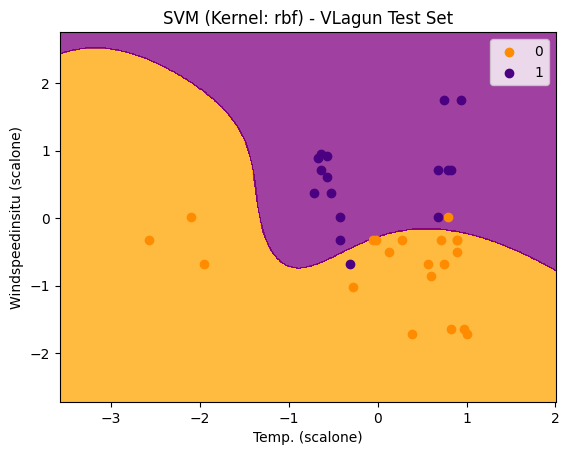

In [10]:
# Wizualizacja zbioru testowego dla VLagun
plot_decision_regions_v(X_test_v, y_test_v, classifier_best_v, f'SVM (Kernel: {best_kernel_v}) - VLagun Test Set')